In [1]:
#6.1
import numpy as np

arr = np.arange(20)

res1 = arr[1::3]

res2 = arr[14:4:-1]

res3 = arr[-1:-6:-1]

print("Каждый третий с индекса 1:", res1)
print("С 5 по 15 (не вкл) в обратном порядке:", res2)
print("Последние 5 в обратном порядке:", res3)

1. Каждый третий с индекса 1: [ 1  4  7 10 13 16 19]
2. С 5 по 15 (не вкл) в обратном порядке: [14 13 12 11 10  9  8  7  6  5]
3. Последние 5 в обратном порядке: [19 18 17 16 15]


In [3]:
#6.2
m6 = np.random.randint(0, 10, size=(6, 6))
print("Исходная матрица:\n", m6)

sub_matrix = m6[1:4, 0:3]
print("\nПодматрица строк 2-4, столбцов 1-3:\n", sub_matrix)

diag = np.diagonal(m6)
print("\nГлавная диагональ:", diag)

mask = (np.indices(m6.shape).sum(axis=0) % 2 == 0)
checkerboard = m6[mask]
print("\nЭлементы с четной суммой индексов (в 1D):", checkerboard)

Исходная матрица:
 [[6 8 4 9 5 4]
 [6 0 9 3 9 9]
 [0 3 3 9 8 8]
 [1 5 0 2 0 6]
 [4 1 6 2 9 9]
 [8 4 8 2 7 2]]

Подматрица строк 2-4, столбцов 1-3:
 [[6 0 9]
 [0 3 3]
 [1 5 0]]

Главная диагональ: [6 0 3 2 9 2]

Элементы с четной суммой индексов (в 1D): [6 4 5 0 3 9 0 3 8 5 2 6 4 6 9 4 2 2]


In [4]:
#6.3
a = np.array([10, 20, 30, 40, 50, 60])
m = np.arange(12).reshape(3, 4)

res_a = a[[0, 2, 4]]
print("Элементы a по индексам [0, 2, 4]:", res_a)

res_m_pairs = m[[0, 1, 2], [1, 3, 0]]
print("Попарные элементы матрицы m:", res_m_pairs)

res_m_block = m[np.ix_([0, 2], [1, 3])]
print("Блок 2x2 из m:\n", res_m_block)

Элементы a по индексам [0, 2, 4]: [10 30 50]
Попарные элементы матрицы m: [1 7 8]
Блок 2x2 из m:
 [[ 1  3]
 [ 9 11]]


In [5]:
#6.4
x = np.random.randn(1000)

count_greater_1 = np.sum(x > 1)
print("Элементов > 1:", count_greater_1)

x_copy = x.copy()
x_copy[x_copy < 0] = 0
print("Первые 10 элементов после замены отрицательных на 0:", x_copy[:10])

sign_change_mask = (x[:-2] * x[2:]) < 0
x[1:-1][sign_change_mask] = 0
print("Элементы на местах смены знака у соседей обнулены")

Элементов > 1: 149
Первые 10 элементов после замены отрицательных на 0: [0.         0.         0.58776278 0.         0.02375022 0.32663309
 0.         0.         1.29158138 0.        ]
Элементы на местах смены знака у соседей обнулены.


In [10]:
#7.1
import os
import numpy as np

filename = 'big.dat'
rows, cols = 50000, 200

mm_w = np.memmap(filename, dtype='float32', mode='w+', shape=(rows, cols))

batch_size = 5000
for i in range(0, rows, batch_size):
    mm_w[i:i+batch_size] = np.random.rand(batch_size, cols)

expected_size = rows * cols * 4
actual_size = os.path.getsize(filename)
print(expected_size == actual_size)

True


In [12]:
#7.2
mm_r = np.memmap(filename, dtype='float32', mode='r', shape=(rows, cols))

global_min = np.inf
global_max = -np.inf
global_sum = 0.0
total_elements = rows * cols

for i in range(0, rows, batch_size):
    chunk = mm_r[i:i+batch_size]
    global_min = min(global_min, chunk.min())
    global_max = max(global_max, chunk.max())
    global_sum += chunk.sum()

global_mean = global_sum / total_elements

print(f"Глобальный Мин: {global_min}")
print(f"Глобальный макс: {global_max}")
print(f"Глобальное среднее: {global_mean}")

Глобальный Мин: 2.868926856081089e-07
Глобальный макс: 0.9999999403953552
Глобальное среднее: 0.4998866021633148


In [15]:
#7.3
import time

n = 3000
arr_c = np.random.rand(n, n) #C-order
arr_f = np.asfortranarray(arr_c) #F-order

def sum_rows_python(arr):
    s = 0.0
    for i in range(n):
        for j in range(n):
            s += arr[i, j]
    return s

def sum_cols_python(arr):
    s = 0.0
    for j in range(n):
        for i in range(n):
            s += arr[i, j]
    return s

start = time.time()
sum_rows_python(arr_c)
print(f"C-order (построчно): {time.time() - start:.4f} сек")

start = time.time()
sum_cols_python(arr_c)
print(f"C-order (постолбцово): {time.time() - start:.4f} сек")

start = time.time()
sum_rows_python(arr_f)
print(f"F-order (построчно): {time.time() - start:.4f} сек")

start = time.time()
sum_cols_python(arr_f)
print(f"F-order (постолбцово): {time.time() - start:.4f} сек")
# F-order работает быстрее

C-order (построчно): 2.9684 сек
C-order (постолбцово): 2.9058 сек
F-order (построчно): 2.0980 сек
F-order (постолбцово): 1.9672 сек


In [16]:
#7.4
N = 10_000_000
a = np.random.rand(N)
b = np.random.rand(N)

a_list = a.tolist()
b_list = b.tolist()
start = time.time()
res_list = [(a_list[i] + b_list[i]) / (a_list[i] - b_list[i] + 1) for i in range(N)]
print(f"Python-цикл с list: {time.time() - start:.4f} сек")

start = time.time()
res_np = (a + b) / (a - b + 1)
print(f"NumPy-выражение в одну строку: {time.time() - start:.4f} сек")

start = time.time()
out = np.empty_like(a)
temp = np.empty_like(a)

np.subtract(a, b, out=temp)       # temp = a - b
np.add(temp, 1, out=temp)         # temp = a - b + 1
np.add(a, b, out=out)             # out = a + b
np.divide(out, temp, out=out)     # out = (a + b) / (a - b + 1)
print(f"NumPy-выражение с out= для переиспользования буфера: {time.time() - start:.4f} сек")

Python list comprehension: 2.8593 сек
NumPy one-liner: 0.1482 сек
NumPy with out= buffer: 0.0904 сек


In [17]:
#8.1
import numpy as np
from scipy.sparse import coo_matrix


np.random.seed(42)
length = 10000
row = np.random.randint(0, 5000, size=length)
col = np.random.randint(0, 5000, size=length)
data = np.random.rand(length)

coo = coo_matrix((data, (row, col)), shape=(5000, 5000))
print(f"Исходное количество элементов в списках: {len(data)}")

csr = coo.tocsr()

print(f"Число ненулевых в CSR после слияния дубликатов: {csr.nnz}")
print(f"дубликатов было: {len(data) - csr.nnz}")

Исходное количество элементов в списках: 10000
Число ненулевых в CSR после слияния дубликатов: 9996
дубликатов было: 4


In [18]:
#8.2
import numpy as np
import scipy.sparse as sp
import time

n = 4000
density = 0.005

A_sparse = sp.random(n, n, density=density, format='csr')
A_dense = A_sparse.toarray()


dense_bytes = A_dense.nbytes
sparse_bytes = A_sparse.data.nbytes + A_sparse.indices.nbytes + A_sparse.indptr.nbytes

print(f"Память Dense: {dense_bytes / (1024**2):.2f} MB")
print(f"Память CSR: {sparse_bytes / (1024**2):.2f} MB")
print(f"CSR экономит память в {dense_bytes / sparse_bytes:.1f} раз(а)")

x = np.random.rand(n)

start = time.time()
for _ in range(10): A_sparse @ x
sparse_time = (time.time() - start) / 10

start = time.time()
for _ in range(10): A_dense @ x
dense_time = (time.time() - start) / 10

print(f"Время умножения Sparse: {sparse_time:.6f} сек")
print(f"Время умножения Dense: {dense_time:.6f} сек")

Память Dense: 122.07 MB
Память CSR: 0.93 MB
CSR экономит память в 131.1 раз(а)
Время умножения Sparse: 0.000153 сек
Время умножения Dense: 0.010110 сек


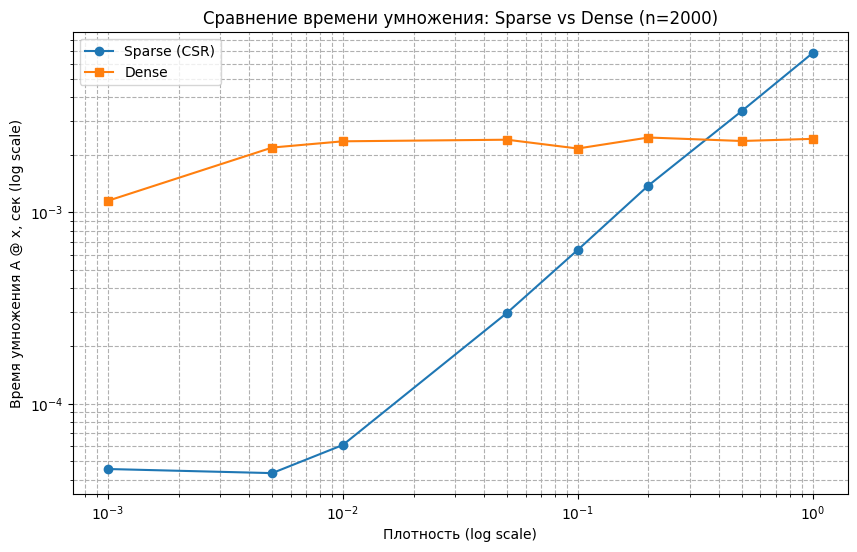

При плотности ~0.5 Sparse начинает проигрывать Dense.


In [19]:
#Задача 8.3
import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
import time

n = 2000
densities = [0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.5, 1.0]
sparse_times = []
dense_times = []

x = np.random.rand(n)

for d in densities:

    A_sp = sp.random(n, n, density=d, format='csr')
    start = time.time()
    for _ in range(5): A_sp @ x
    sparse_times.append((time.time() - start) / 5)

    A_de = A_sp.toarray()
    start = time.time()
    for _ in range(5): A_de @ x
    dense_times.append((time.time() - start) / 5)

plt.figure(figsize=(10, 6))
plt.plot(densities, sparse_times, marker='o', label='Sparse (CSR)')
plt.plot(densities, dense_times, marker='s', label='Dense')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Плотность (log scale)')
plt.ylabel('Время умножения A @ x, сек (log scale)')
plt.title('Сравнение времени умножения: Sparse vs Dense (n=2000)')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

for d, st, dt in zip(densities, sparse_times, dense_times):
    if st > dt:
        print(f"При плотности ~{d} Sparse начинает проигрывать Dense.")
        break